Saving 10748723-many-different-coins-collection-on-white-background.jpg to 10748723-many-different-coins-collection-on-white-background.jpg


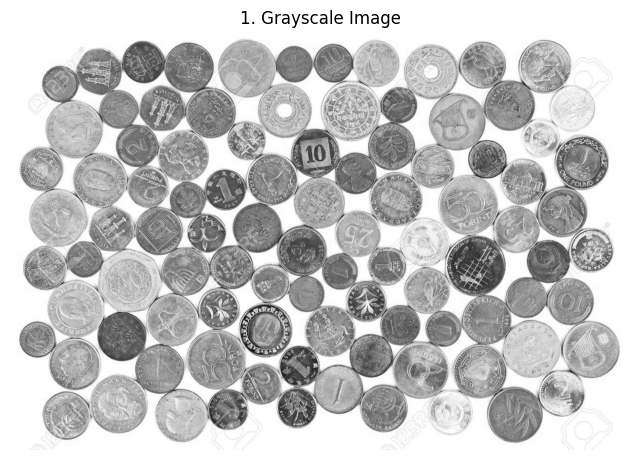

In [45]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 사진 직접 업로드
uploaded = files.upload()

# 업로드한 파일 이름 가져오기
filename = next(iter(uploaded))

# 이미지 불러오기
img = cv2.imread(filename)

if img is None:
    raise FileNotFoundError("Image not found")

# Grayscale 변환
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(8, 10))
plt.imshow(gray, cmap='gray')
plt.title('1. Grayscale Image')
plt.axis('off')
plt.show()

In [2]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/class/DIP1/DIP4E'

Mounted at /content/drive


## 1. object counting에 사용할 image를 grayscale로 불러오기

Saving 10748723-many-different-coins-collection-on-white-background.jpg to 10748723-many-different-coins-collection-on-white-background (1).jpg


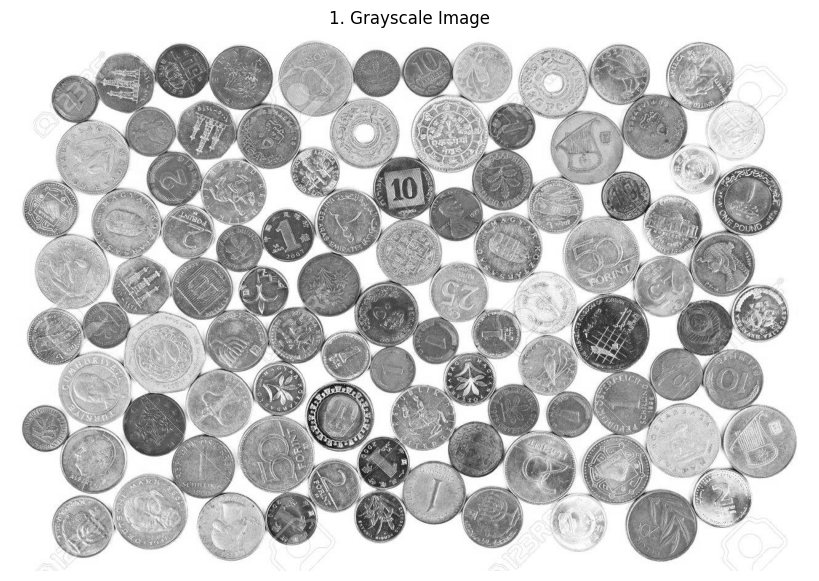

In [72]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload image
uploaded = files.upload()
filename = next(iter(uploaded))

# Read image as grayscale
f = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(12, 7))
plt.imshow(f, cmap='gray')
plt.title('1. Grayscale Image')
plt.axis('off')
plt.show()

## 2. 적절한 전처리를 통해 영상의 noise를 줄이기

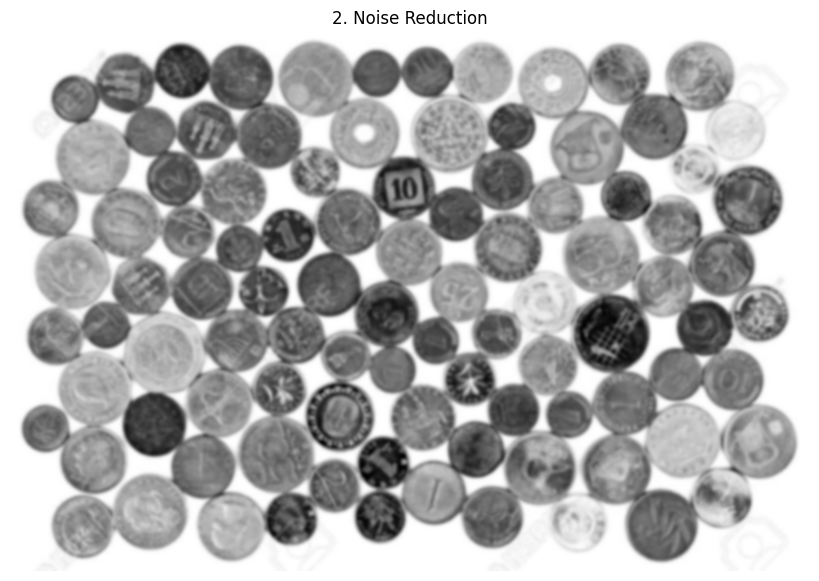

In [84]:
f_denoised = cv2.GaussianBlur(f, (15, 15), 0)

plt.figure(figsize=(12, 7))
plt.imshow(f_denoised, cmap='gray')
plt.title('2. Noise Reduction')
plt.axis('off')
plt.show()

## 3. 적절한 임계값을 찾아 thresholding을 통해 binary mask를 생성하기

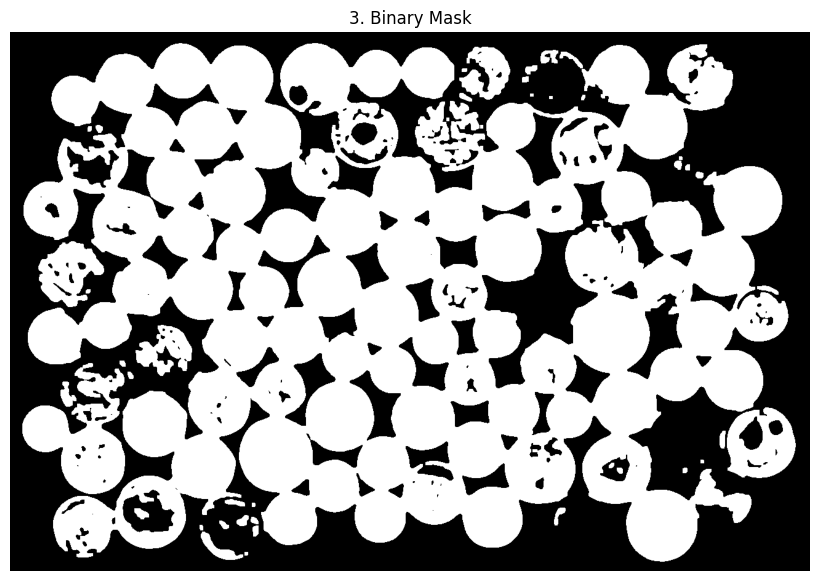

In [111]:
# Otsu Thresholding
th_val, f_mask = cv2.threshold(
    f_denoised,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Remove small noise
kernel = np.ones((3, 3), np.uint8)

f_mask = cv2.morphologyEx(
    f_mask,
    cv2.MORPH_OPEN,
    kernel,
    iterations=2
)

plt.figure(figsize=(12, 7))
plt.imshow(f_mask, cmap='gray')
plt.title('3. Binary Mask')
plt.axis('off')
plt.show()

## 4. Connected component 추출을 통해 object를 분리하고, 각각의 pixel수를 계산하기

In [112]:
# Distance Transform
dist = cv2.distanceTransform(
    f_mask,
    cv2.DIST_L2,
    5
)

# Find sure foreground
_, sure_fg = cv2.threshold(
    dist,
    0.35 * dist.max(),
    255,
    0
)

sure_fg = np.uint8(sure_fg)

# Find sure background
kernel = np.ones((3, 3), np.uint8)

sure_bg = cv2.dilate(
    f_mask,
    kernel,
    iterations=3
)

# Unknown region
unknown = cv2.subtract(sure_bg, sure_fg)

# Connected Component for markers
nums, markers = cv2.connectedComponents(sure_fg)

markers = markers + 1
markers[unknown == 255] = 0

# Apply Watershed
img_color = cv2.imread(filename)

labels_ws = cv2.watershed(
    img_color,
    markers
)

# Extract separated objects
labels = labels_ws.copy()

# Watershed boundaries and background excluded
labels[labels <= 1] = 0
labels[labels > 1] -= 1

# Calculate pixel counts
valid_labels = np.unique(labels)
valid_labels = valid_labels[valid_labels > 0]

cc = np.zeros((len(valid_labels), 2))

for j, i in enumerate(valid_labels):
    cc[j, 0] = i
    cc[j, 1] = np.sum(labels == i)

    print(
        f'index: {int(cc[j,0])}, '
        f'number of pixels: {int(cc[j,1])}'
    )

print("Total objects:", len(cc))

index: 1, number of pixels: 8215
index: 2, number of pixels: 5900
index: 3, number of pixels: 8346
index: 4, number of pixels: 7108
index: 5, number of pixels: 4870
index: 6, number of pixels: 4446
index: 7, number of pixels: 7000
index: 8, number of pixels: 4130
index: 9, number of pixels: 4434
index: 10, number of pixels: 8570
index: 11, number of pixels: 6930
index: 12, number of pixels: 8489
index: 13, number of pixels: 4427
index: 14, number of pixels: 5089
index: 15, number of pixels: 1061
index: 16, number of pixels: 478
index: 17, number of pixels: 7552
index: 18, number of pixels: 6239
index: 19, number of pixels: 7794
index: 20, number of pixels: 8141
index: 21, number of pixels: 1957
index: 22, number of pixels: 9113
index: 23, number of pixels: 4515
index: 24, number of pixels: 1747
index: 25, number of pixels: 1
index: 26, number of pixels: 178
index: 27, number of pixels: 5885
index: 28, number of pixels: 8318
index: 29, number of pixels: 4809
index: 30, number of pixels:

In [62]:
num_labels, labels, stats, centroids = \
    cv2.connectedComponentsWithStats(
        binary, connectivity=8
    )

objects = []

for i in range(1, num_labels):
    area = stats[i, cv2.CC_STAT_AREA]

    if 50 <= area <= 10000:
        objects.append((i, area))

print("Total Objects:", len(objects))

for label, pixels in objects:
    print(f"Object {label}: {pixels} pixels")

Total Objects: 145
Object 1: 286 pixels
Object 2: 2568 pixels
Object 3: 857 pixels
Object 4: 194 pixels
Object 6: 324 pixels
Object 9: 133 pixels
Object 13: 914 pixels
Object 14: 291 pixels
Object 16: 390 pixels
Object 18: 69 pixels
Object 23: 350 pixels
Object 25: 63 pixels
Object 27: 147 pixels
Object 31: 161 pixels
Object 36: 419 pixels
Object 37: 103 pixels
Object 38: 159 pixels
Object 41: 612 pixels
Object 48: 177 pixels
Object 49: 108 pixels
Object 50: 217 pixels
Object 53: 71 pixels
Object 56: 333 pixels
Object 64: 50 pixels
Object 67: 9323 pixels
Object 70: 88 pixels
Object 76: 141 pixels
Object 79: 83 pixels
Object 81: 59 pixels
Object 83: 151 pixels
Object 88: 53 pixels
Object 89: 169 pixels
Object 92: 98 pixels
Object 93: 108 pixels
Object 96: 65 pixels
Object 103: 100 pixels
Object 105: 183 pixels
Object 106: 909 pixels
Object 107: 71 pixels
Object 114: 73 pixels
Object 117: 170 pixels
Object 119: 79 pixels
Object 123: 215 pixels
Object 124: 70 pixels
Object 125: 81 pixels


## 5. 추출한 connected component 중 가장 큰 것과 작은 것을 시각화하기

In [107]:
ind_max = np.argmax(cc[:, 1])
ind_min = np.argmin(cc[:, 1])

print("Largest index:", ind_max)
print("Smallest index:", ind_min)

Largest index: 0
Smallest index: 6


Detected coins: 49
Largest: 11833 pixels
Smallest: 4382 pixels


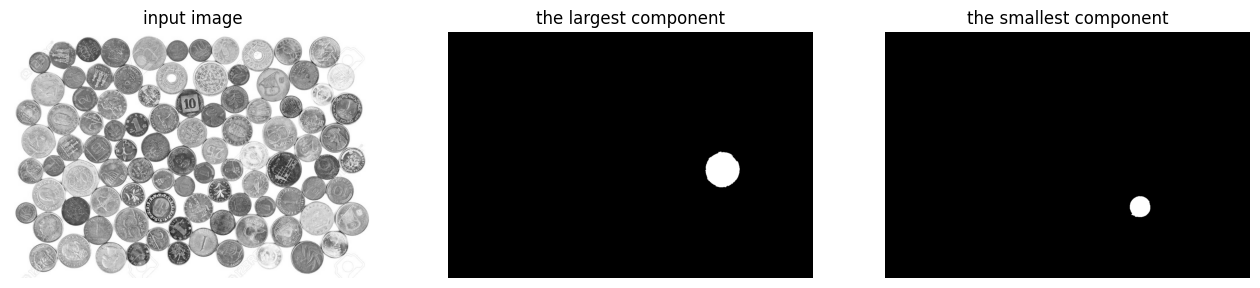

In [117]:
valid_objects = []

for i in np.unique(labels):

    if i <= 0:
        continue

    mask = (labels == i).astype(np.uint8)
    area = cv2.countNonZero(mask)

    # 최소 면적 기준 강화
    if area < 2000:
        continue

    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if len(contours) == 0:
        continue

    contour = max(contours, key=cv2.contourArea)

    perimeter = cv2.arcLength(contour, True)

    if perimeter == 0:
        continue

    circularity = 4 * np.pi * cv2.contourArea(contour) / (perimeter ** 2)

    x, y, w, h = cv2.boundingRect(contour)
    aspect_ratio = w / h

    # Stricter coin selection
    if circularity > 0.65 and 0.80 < aspect_ratio < 1.25:
        valid_objects.append([i, area])

cc = np.array(valid_objects)

if len(cc) >= 2:

    ind_max = np.argmax(cc[:, 1])
    ind_min = np.argmin(cc[:, 1])

    print("Detected coins:", len(cc))
    print("Largest:", int(cc[ind_max, 1]), "pixels")
    print("Smallest:", int(cc[ind_min, 1]), "pixels")

    plt.figure(figsize=(16, 9))

    plt.subplot(131)
    plt.imshow(f, cmap='gray')
    plt.axis('off')
    plt.title('input image')

    plt.subplot(132)
    plt.imshow(labels == int(cc[ind_max, 0]), cmap='gray')
    plt.axis('off')
    plt.title('the largest component')

    plt.subplot(133)
    plt.imshow(labels == int(cc[ind_min, 0]), cmap='gray')
    plt.axis('off')
    plt.title('the smallest component')

    plt.show()

else:
    print("Not enough coin-like objects detected.")

NameError: name 'f' is not defined

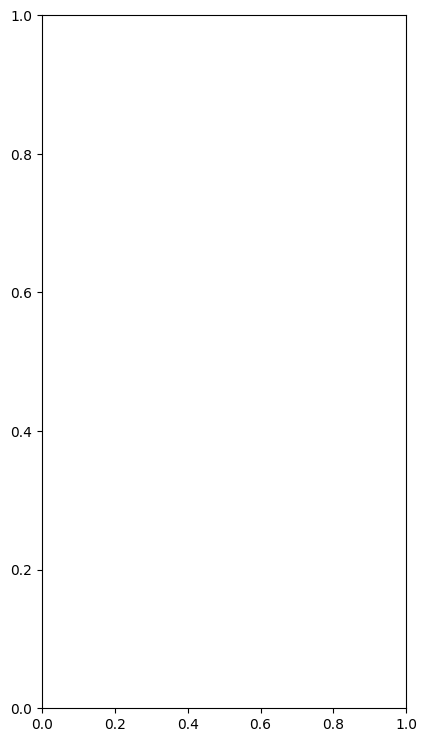